# 06 · Topic modelling — what are guests talking about?
**Approach.** Reviews mention several aspects ("the spa was great, check-in was slow"), so topics are found at
**sentence level**. Two methods are compared:

1. **Seeded (guided) topics** — each sentence is assigned to the project's nine categories (*staff, service,
   cleanliness, facilities, food, location, room quality, pricing, comfort*) via reviewable seed lexicons; sentences with
   no match become *General / Overall*.
2. **Unsupervised NMF** — a standard clustering baseline with k = 6…16.

Why not just cluster? On this data plain clustering is dominated by sentiment phrasing and boilerplate
("great start", "wouldn't recommend") rather than aspects — the comparison below shows it. Transformer-based
BERTopic is in notebook 07. Both methods are scored with **NPMI coherence** and logged to MLflow.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, re
from pathlib import Path
import mlflow, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, OUT = ROOT / "data" / "processed", ROOT / "outputs"
TOP = OUT / "topics"; TOP.mkdir(parents=True, exist_ok=True)
SEED = 42
MLFLOW_URI = f"sqlite:///{ROOT / 'mlflow.db'}"
GENERAL = "General / Overall"
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
df = pd.read_csv(PROC / "reviews_full.csv")

## 1. Sentence segmentation
City names are masked so topics are not driven by place names ("Our stay in *London*…").

In [2]:
def split_sentences(df, locations):
    locs = sorted(set(map(str, locations)), key=len, reverse=True)
    loc_rx = re.compile(r"\b(" + "|".join(map(re.escape, locs)) + r")\b", re.I)
    s = df[["review_id", "review_text"]].copy()
    s["sentence"] = s.review_text.str.split(r"(?<=[.!?])\s+")
    s = s.explode("sentence").drop(columns="review_text")
    s["sentence"] = s.sentence.fillna("").str.strip()
    s = s[s.sentence.str.len() > 2].reset_index(drop=True)
    s["sent_idx"] = s.groupby("review_id").cumcount()
    s["masked"] = s.sentence.str.replace(loc_rx, " ", regex=True).str.replace(r"(?i)wi[- ]fi", "wifi", regex=True)
    return s

sent = split_sentences(df, df.location.dropna().unique())
sent.to_csv(TOP / "sentences.csv", index=False)
print(f"{len(df):,} reviews → {len(sent):,} sentences ({sent.masked.nunique():,} unique)")
sent.sample(5, random_state=3)[["review_id", "sentence"]]

34,460 reviews → 85,030 sentences (24,350 unique)


,review_id,sentence
23649,9668,"The concierge was adequate, nothing more and nothing less."
57259,23514,"The common area was passably clean, nothing more and nothing less."
31981,13078,"Overall the manager was reasonably polite, about what we expected."
20203,8240,"Meanwhile, the breakfast was fine, nothing more and nothing less."
36730,15042,We had a wonderful time during our stay in Edinburgh.


## 2. Seed lexicons (edit these!)
The lexicons are the *interpretable, auditable* part of the method: a hotel analyst can read and extend them.
A sentence is assigned to the category (or categories, on ties) with the most seed hits.

In [3]:
SEEDS = {
    "Staff": [r"\bstaff\b", r"receptionist", r"\breception\b", r"concierge", r"\bmanager", r"\bteam\b",
              r"\bporter", r"personnel", r"employees?", r"\bpolite", r"\brude\b", r"\bfriendly\b"],
    "Service": [r"\bcheck(?:ed|ing)?[- ]?(?:in|out)?\b", r"\barrival\b", r"\bqueue", r"\bwait(?:ed|ing)?\b",
                r"room service", r"\bservice\b", r"\bkeys?\b", r"\brespon(?:d|se|sive)", r"\brequests?\b",
                r"\bslow(?:ly)?\b", r"disorganis?ed"],
    "Cleanliness": [r"\bclean\w*", r"spotless", r"\bdust\w*", r"grim\w+", r"\btidy\b", r"scrubbed", r"unkempt",
                    r"\bdirt\w*", r"\bstain\w*", r"\bsmell\w*", r"\bodou?r", r"hygien\w+", r"housekeeping",
                    r"neglected", r"\bmould", r"sanitis\w+"],
    "Facilities": [r"\bspa\b", r"\bgym\b", r"\bpool\b", r"fitness", r"facilit\w+", r"wi[- ]?fi", r"\bparking\b",
                   r"car park", r"\blifts?\b", r"elevators?", r"\blounge\b", r"business cent\w+", r"common area",
                   r"\bsauna\b", r"laundry", r"amenit\w+"],
    "Food": [r"breakfast", r"buffet", r"\brestaurant\b", r"caf[eé]", r"\bdining\b", r"pastr\w+", r"\bportions?\b",
             r"\bfood\b", r"\bmeals?\b", r"\bmenu\b", r"\bcoffee\b", r"\bbar\b", r"dinner", r"lunch", r"edible",
             r"\btaste\w*", r"\bdrinks?\b"],
    "Location": [r"location", r"neighbou?rhood", r"surrounding\w*", r"transport", r"\bcentral\w*", r"\bnearby\b",
                 r"walking distance", r"convenien\w+", r"\bshops\b", r"\bsituated\b", r"\bplaced\b", r"hard to reach",
                 r"getting around", r"\bbase\b", r"\bride\b", r"restaurants shops"],
    "Room quality": [r"\brooms?\b(?! service)", r"bathroom", r"bedding", r"\bbeds?\b", r"carpet", r"d[eé]cor",
                     r"\bsuite\b", r"shower", r"furnish\w*", r"linens?", r"towels?", r"wallpaper"],
    "Pricing": [r"\bpric\w+", r"\bcosts?\b", r"\brates?\b", r"\bvalue\b", r"overpriced", r"bargain", r"afford\w+",
                r"\bcharge\w*", r"\bfares?\b", r"\bpaid\b", r"\bdeals?\b", r"\brip[- ]?off\b", r"\brip\b",
                r"expensive", r"\bcheap\w*", r"\bmoney\b"],
    "Comfort": [r"comfort\w*", r"mattress", r"pillows?", r"\bnois\w+", r"\bloud\b", r"\bquiet\b", r"temperature",
                r"air[- ]?con\w*", r"heating", r"\bco[sz]y\b", r"spacious", r"cramped", r"\bsleep\w*"],
}
(TOP / "seeds.json").write_text(json.dumps(SEEDS, indent=1))           # reused by notebook 07
SEED_RX = {c: [re.compile(p, re.I) for p in ps] for c, ps in SEEDS.items()}

def assign_seeded(texts):
    """Multi-label: every category tied for the highest seed-hit count; no hit → GENERAL."""
    rows = []
    for i, t in texts.items():
        h = {c: sum(len(rx.findall(t)) for rx in rxs) for c, rxs in SEED_RX.items()}
        m = max(h.values())
        for c in ([c for c, v in h.items() if v == m] if m > 0 else [GENERAL]):
            rows.append((i, c, m))
    return pd.DataFrame(rows, columns=["row", "category", "hits"])

a = assign_seeded(sent.masked)
a["review_id"] = sent.loc[a.row, "review_id"].values
a["sent_idx"] = sent.loc[a.row, "sent_idx"].values
a["sentence"] = sent.loc[a.row, "sentence"].values
a[["review_id", "sent_idx", "sentence", "category", "hits"]].to_csv(TOP / "sentence_topics.csv", index=False)
cover = 1 - (a.category == GENERAL).sum() / len(sent)
print(f"coverage: {100 * cover:.1f}% of sentences get a named topic")

coverage: 72.0% of sentences get a named topic


## 3. Coherence helper and topic summary table
NPMI coherence: average normalised pointwise mutual information between a topic's top terms, measured on
sentence co-occurrence (higher = terms appear together more than chance).

In [4]:
cv = CountVectorizer(min_df=5, stop_words="english", binary=True)
B = cv.fit_transform(sent.masked)
vocab = list(cv.get_feature_names_out()); vindex = {t: i for i, t in enumerate(vocab)}

def npmi_coherence(topic_terms):
    N = B.shape[0]; df_ = np.asarray(B.sum(0)).ravel(); out = []
    for terms in topic_terms:
        idx = [vindex[t] for t in terms if t in vindex]
        if len(idx) < 2: out.append(np.nan); continue
        sub = B[:, idx]; co = (sub.T @ sub).toarray() / N; p = df_[idx] / N; vals = []
        for i in range(len(idx)):
            for j in range(i + 1, len(idx)):
                pij = co[i, j]; vals.append(-1.0 if pij <= 0 else np.log(pij / (p[i] * p[j])) / -np.log(pij))
        out.append(float(np.mean(vals)))
    return out

def top_terms_by_kl(mask, k=10, min_df=15):
    """Terms that characterise a set of sentences: p(t|topic)·log(p(t|topic)/p(t))."""
    N = B.shape[0]; df_all = np.asarray(B.sum(0)).ravel(); df_in = np.asarray(B[mask].sum(0)).ravel()
    p_in, p_all = df_in / max(mask.sum(), 1), df_all / N
    with np.errstate(divide="ignore", invalid="ignore"):
        score = np.where((df_in >= min_df) & (p_in > p_all), p_in * np.log(p_in / p_all), 0)
    return [vocab[i] for i in np.argsort(-score)[:k] if score[i] > 0]

info, sugg = [], []
for c in list(SEEDS) + [GENERAL]:
    mask = np.zeros(len(sent), bool); mask[a.loc[a.category == c, "row"].values] = True
    info.append({"category": c, "n_sentences": int(mask.sum()), "n_reviews": int(a.loc[a.category == c, "review_id"].nunique()),
                 "pct_sentences": round(100 * mask.mean(), 1), "top_terms": ", ".join(top_terms_by_kl(mask))})
    if c != GENERAL:      # candidates the analyst may add to the seed list
        for tt in top_terms_by_kl(mask, k=25):
            if not any(re.search(p, tt, re.I) for p in SEEDS[c]): sugg.append({"category": c, "candidate_term": tt})
info = pd.DataFrame(info)
info["npmi_coherence"] = np.round(npmi_coherence([r.split(", ") for r in info.top_terms]), 3)
info.to_csv(TOP / "topic_info.csv", index=False)
pd.DataFrame(sugg).to_csv(TOP / "keyword_suggestions.csv", index=False)
info

,category,n_sentences,n_reviews,pct_sentences,top_terms,npmi_coherence
0,Staff,9324,9162,11.0,"staff, team, receptionist, concierge, manager, night, professional, housekeeping, service, polite",-0.283
1,Service,12145,11529,14.3,"arrival, check, service, checked, process, desk, room, experience, getting, average",-0.226
2,Cleanliness,6725,6596,7.9,"clean, bathroom, housekeeping, spotless, staff, area, carpet, passably, common, suite",0.012
3,Facilities,9665,9421,11.4,"lounge, spa, gym, pool, center, wifi, facilities, fitness, business, functional",-0.642
4,Food,6931,6897,8.2,"restaurant, breakfast, buffet, cafe, house, dining, options, write, home, decent",-0.245
5,Location,9813,9508,11.5,"location, neighborhood, surrounding, area, convenient, central, getting, better, base, visiting",-0.461
6,Room quality,7017,6979,8.3,"bathroom, clean, carpet, suite, décor, bedding, room, overall, tidy, passably",-0.106
7,Pricing,15292,13596,18.0,"paid, price, cost, rate, pricing, hotels, similar, quality, reasonable, overall",0.254
8,Comfort,353,353,0.4,"spacious, spotless, rarely, peak, crowded, condition, times, kept, looked, wifi",0.104
9,General / Overall,23812,21143,28.0,"time, visit, recommend, trip, start, choice, hotel, got, stay, great",-0.512


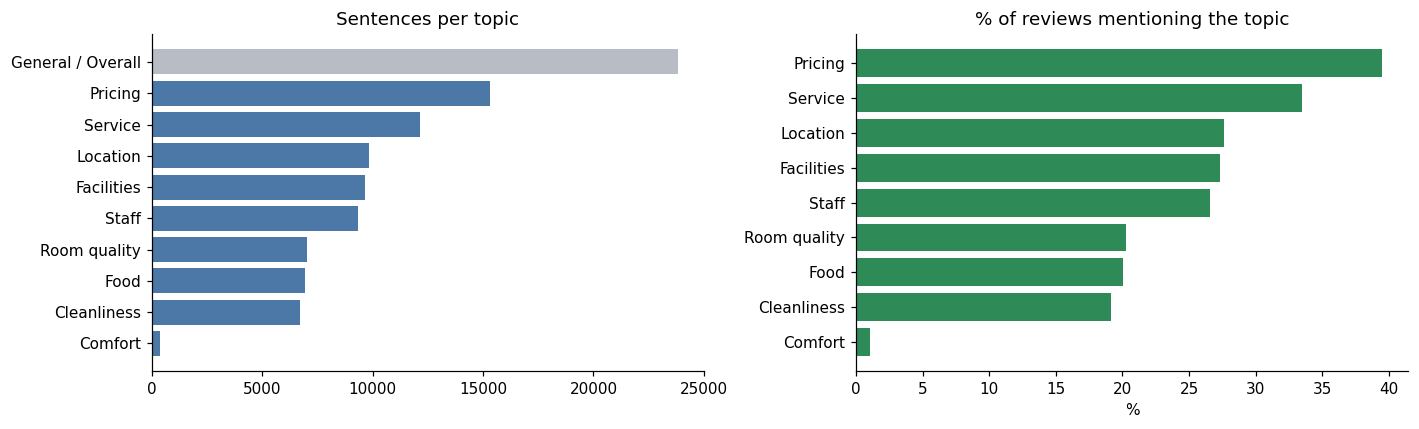

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ii = info.sort_values("n_sentences")
ax[0].barh(ii.category, ii.n_sentences, color=["#B8BCC4" if c == GENERAL else "#4C78A8" for c in ii.category])
ax[0].set_title("Sentences per topic")
rv = info[info.category != GENERAL].sort_values("n_reviews")
ax[1].barh(rv.category, 100 * rv.n_reviews / df.review_id.nunique(), color="#2E8B57")
ax[1].set(title="% of reviews mentioning the topic", xlabel="%"); plt.tight_layout(); plt.show()

### What is left in "General / Overall"?
A sanity check that the seeds are not missing a real aspect:

In [6]:
g = a[a.category == GENERAL].sentence.str.replace(r"\b(" + "|".join(df.location.dropna().unique()) + r")\b", "<city>", regex=True)
g.value_counts().head(12).rename("sentences").to_frame()

,sentences
sentence,
Nothing about our visit to <city> stood out much either way.,1869
"This hotel was a fine, if unremarkable, choice for our time in <city>.",1864
Our stay in <city> was fairly ordinary.,1861
We had a wonderful time during our stay in <city>.,1156
Would neither recommend nor avoid it.,1154
Our trip to <city> got off to a great start here.,1131
This hotel made our time in <city> truly memorable.,1107
"Might consider it again, might not.",1069
An okay option if nothing else is available.,982


**Reading:** the leftovers are overall impressions, recommendations and trip purpose — not missed aspects.
The `keyword_suggestions.csv` file lists data-driven candidate terms to extend each lexicon.

## 4. Unsupervised baseline: NMF sweep
TF-IDF + NMF for k = 6…16 on the same sentences, scored with the same coherence function.

2026/10/10 20:31:26 INFO mlflow.tracking.fluent: Experiment with name 'guest-topic-modelling' does not exist. Creating a new experiment.


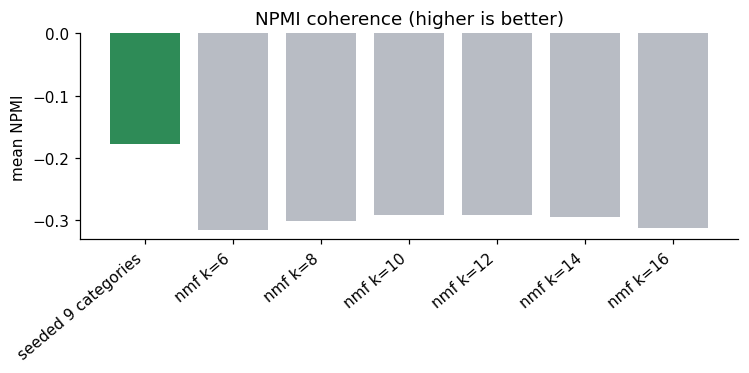

,method,config,n_topics,npmi_coherence,coverage
0,seeded,9 categories,9,-0.177,0.72
1,nmf,k=6,6,-0.315,1.00
2,nmf,k=8,8,-0.300,1.00
3,nmf,k=10,10,-0.291,1.00
4,nmf,k=12,12,-0.292,1.00
5,nmf,k=14,14,-0.294,1.00
6,nmf,k=16,16,-0.312,1.00


In [7]:
mlflow.set_tracking_uri(MLFLOW_URI); mlflow.set_experiment("guest-topic-modelling")
named = info[info.category != GENERAL]
exp = [{"method": "seeded", "config": f"{len(SEEDS)} categories", "n_topics": len(SEEDS),
        "npmi_coherence": float(np.nanmean(named.npmi_coherence)), "coverage": cover}]
with mlflow.start_run(run_name="seeded_lexicon"):
    mlflow.log_params({"method": "seeded", "n_categories": len(SEEDS), "n_sentences": len(sent)})
    mlflow.log_metrics({"npmi_coherence_mean": exp[0]["npmi_coherence"], "coverage": cover})

tv = TfidfVectorizer(min_df=5, max_df=0.2, stop_words="english", sublinear_tf=True)
X = tv.fit_transform(sent.masked); tvocab = np.array(tv.get_feature_names_out())
nmf_terms = {}
for k in (6, 8, 10, 12, 14, 16):
    nmf = NMF(k, random_state=SEED, init="nndsvda", max_iter=400).fit(X)
    tops = [list(tvocab[c.argsort()[-10:][::-1]]) for c in nmf.components_]
    nmf_terms[k] = tops
    sc = float(np.nanmean(npmi_coherence(tops)))
    with mlflow.start_run(run_name=f"nmf_k{k}"):
        mlflow.log_params({"method": "nmf", "k": k}); mlflow.log_metric("npmi_coherence_mean", sc)
    exp.append({"method": "nmf", "config": f"k={k}", "n_topics": k, "npmi_coherence": sc, "coverage": 1.0})
exp = pd.DataFrame(exp); exp.to_csv(TOP / "topic_experiments.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(exp.method + " " + exp.config, exp.npmi_coherence, color=["#2E8B57"] + ["#B8BCC4"] * (len(exp) - 1))
ax.set(title="NPMI coherence (higher is better)", ylabel="mean NPMI"); plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()
exp.round(3)

**How to read the coherence numbers.** All are negative: NPMI rewards words that share a *sentence*, but aspect
topics are made of synonyms/co-hyponyms (spa / gym / pool) that rarely appear together. The seeded topics score slightly
higher, but the gap is small — so judge methods on **interpretability and coverage** as well. Compare the NMF topics with the
seeded ones:

In [8]:
pd.DataFrame({"NMF k=10 topic": range(10), "top terms": [", ".join(t[:8]) for t in nmf_terms[10]]})

,NMF k=10 topic,top terms
0,0,"expected, overall, price, experience, acceptable, wasn, fine, arrival"
1,1,"hotel, time, fine, unremarkable, choice, truly, memorable, getting"
2,2,"ordinary, fairly, stay, professional, tidy, happened, bathroom, area"
3,3,"visit, way, stood, wasn, experience, expected, disappointingly, went"
4,4,"start, got, trip, great, rocky, time, perfect, conference"
5,5,"paid, acceptable, rate, area, plus, hand, check, addition"
6,6,"recommend, avoid, wouldn, highly, travelers, consider, left, turned"
7,7,"stay, wonderful, really, affected, time, planned, didn, definitely"
8,8,"genuinely, impressed, great, honestly, excellent, staff, plus, spotless"
9,9,"asked, base, visiting, couldn, better, did, options, nearby"


Several NMF topics are generic phrasing ("great start", "recommend avoid", "ordinary fairly") rather than hotel aspects —
which is why the seeded categories are used downstream (notebooks 08–09). For a transformer-based alternative,
see notebook 07.